# Week 4 · Task 1.1 / 1.2 follow-up — Per-bin significance tests

The size-stratified (Task 1.1) and contrast-stratified (Task 1.2) tables are descriptive means. This notebook adds the paired bootstrap confidence intervals and Wilcoxon tests per bin, using the same conventions as Sebastian's `src/stats_analysis.py`.

**Conventions (same as the shared protocol).**
- Unit of analysis: the test image. The U-Net score of an image in a bracket is the mean over the 3 seeds; it is paired with the single SAM 3 score for the same image.
- Effect = **SAM 3 advantage**: `SAM 3 - U-Net` for Dice, IoU and Boundary IoU (higher is better); `U-Net - SAM 3` for HD95 (lower is better). Positive therefore always means SAM 3 is better.
- 95 % CI: percentile bootstrap over images, 10,000 resamples (`configs/eval.yaml`), fixed seed. Image resampling only: the seed stage of the two-stage bootstrap is not repeated here (3 seeds are averaged first).
- Test: two-sided Wilcoxon signed-rank on the paired differences. Rank-biserial `r` is the effect size (positive = SAM 3 better).
- HD95: non-finite values capped at the largest finite value in the data (policy logged in `decisions.md`, 21 Oct); summary = median of paired differences.
- Multiple comparisons: p-values are adjusted within each metric across all bins, brackets and strategies, with both Holm and Bonferroni. Quote Holm unless the group agrees otherwise. Size bins are the pre-declared analysis; contrast bins are exploratory.
- Strategies tested: `box-gt` (oracle), `box-j10` (realistic box), `pt-3`. Fewer strategies keeps the number of tests, and the multiplicity penalty, manageable.

**Check.** The cell below reproduces Sebastian's all-image Wilcoxon results before any bin is analysed.

**Power.** The small bin has only 39 images, so wide intervals and non-significant results there are expected and should be reported as inconclusive, not as "no difference".

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "results" / "week4"
OUT.mkdir(parents=True, exist_ok=True)

N_BOOT = 10_000
BOOT_SEED = 20260101
STRATEGIES = ["box-gt", "box-j10", "pt-3"]
BRACKETS = ["10pct", "25pct", "50pct", "100pct"]
METRICS = {"dice": +1, "boundary_iou": +1, "hd95": -1}     # direction: +1 higher is better, -1 lower is better
SIZE_ORDER = ["small", "medium", "large"]
CONTRAST_ORDER = ["low", "medium", "high"]

## 1. Build the paired per-image table

In [2]:
df = pd.read_csv(ROOT / "results" / "per_image_results.csv")
df["hd95"] = df["hd95"].replace([np.inf, -np.inf], np.nan)
finite_max = df["hd95"].max()
n_nonfinite = int(df["hd95"].isna().sum())
df["hd95"] = df["hd95"].fillna(finite_max)
print(f"HD95: {n_nonfinite} non-finite rows capped at {finite_max:.3f}")

df["bracket"] = df.run_id.str.extract(r"^(.+?)[_-]seed\d+$")[0]
# SAM 3 scores: one per image and strategy
sam = {m: df[df.arm == "sam3"].pivot(index="image_id", columns="run_id", values=m) for m in METRICS}
# U-Net scores: mean over seeds per image and bracket
unet = {m: df[df.arm == "unet"].groupby(["image_id", "bracket"])[m].mean().unstack() for m in METRICS}
images = sorted(sam["dice"].index)
assert len(images) == 200 and all(unet[m].shape == (200, 4) for m in METRICS)

size = pd.read_csv(ROOT / "results" / "week4" / "size_bin_assignment.csv").set_index("image_id")["size_bin"]
contrast = pd.read_csv(ROOT / "results" / "week4" / "contrast_per_image.csv").set_index("image_id")["contrast_bin"]
print(size.value_counts().reindex(SIZE_ORDER).to_dict(), contrast.value_counts().reindex(CONTRAST_ORDER).to_dict())

HD95: 19 non-finite rows capped at 601.465
{'small': 39, 'medium': 81, 'large': 80} {'low': 67, 'medium': 66, 'high': 67}


## 2. Test function

In [3]:
def advantage(metric, bracket, strategy, ids):
    s = sam[metric].loc[ids, strategy].to_numpy(float)
    u = unet[metric].loc[ids, bracket].to_numpy(float)
    return (s - u) if METRICS[metric] > 0 else (u - s)       # positive = SAM 3 better

def summarise(d, metric, rng):
    stat = np.median if metric == "hd95" else np.mean
    est = stat(d)
    idx = rng.integers(0, len(d), size=(N_BOOT, len(d)))
    boots = stat(d[idx], axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    nz = d[d != 0]
    if len(nz) == 0:
        p, r = 1.0, 0.0
    else:
        p = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided").pvalue
        ranks = stats.rankdata(np.abs(nz))
        wp, wn = ranks[nz > 0].sum(), ranks[nz < 0].sum()
        r = (wp - wn) / (wp + wn)
    return est, lo, hi, p, r, float((d < 0).mean())     # last = share of images where U-Net is better

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

## 3. Check against Sebastian's all-image tests

For the unstratified 200 images, my Wilcoxon p-values, effect sizes and median differences must match `results/analysis/wilcoxon.csv`. His `median_diff` is U-Net minus SAM 3 for Dice, so the sign is flipped here.

In [4]:
rng = np.random.default_rng(BOOT_SEED)
seb = pd.read_csv(ROOT / "results" / "analysis" / "wilcoxon.csv")
rows = []
for b in BRACKETS:
    for s in STRATEGIES:
        d = advantage("dice", b, s, images)
        est, lo, hi, p, r, _ = summarise(d, "dice", rng)
        ref = seb[(seb.metric == "dice") & (seb.unet_bracket == b) & (seb.sam3_strategy == s)].iloc[0]
        rows.append({"bracket": b, "strategy": s, "p_mine": p, "p_seb": ref.p_raw,
                     "median_adv_mine": np.median(d), "median_adv_seb(-diff)": -ref.median_diff,
                     "|r|_mine": abs(r), "|r|_seb": abs(ref.rank_biserial)})
chk = pd.DataFrame(rows)
ok_p = np.allclose(chk.p_mine, chk.p_seb, rtol=1e-6, atol=1e-12)
ok_m = np.allclose(chk["median_adv_mine"], chk["median_adv_seb(-diff)"], atol=1e-9)
ok_r = np.allclose(chk["|r|_mine"], chk["|r|_seb"], atol=1e-4)
print("p-values match:", ok_p, "| median differences match:", ok_m, "| effect sizes match:", ok_r)
chk

p-values match: True | median differences match: True | effect sizes match: True


,bracket,strategy,p_mine,p_seb,median_adv_mine,median_adv_seb(-diff),|r|_mine,|r|_seb
0,10pct,box-gt,6.456319e-18,6.456319e-18,0.089083,0.089083,0.703284,0.703284
1,10pct,box-j10,4.514722e-09,4.514722e-09,0.064687,0.064687,0.478209,0.478209
2,10pct,pt-3,4.414114e-12,4.414114e-12,0.051329,0.051329,0.564577,0.564577
3,25pct,box-gt,4.263979e-15,4.263979e-15,0.049057,0.049057,0.639900,0.639900
4,25pct,box-j10,1.756574e-05,1.756574e-05,0.019506,0.019506,0.350149,0.350149
5,25pct,pt-3,5.173066e-07,5.173066e-07,0.031992,0.031992,0.409353,0.409353
6,50pct,box-gt,1.058432e-10,1.058432e-10,0.034027,0.034027,0.526667,0.526667
7,50pct,box-j10,1.032360e-02,1.032360e-02,0.008035,0.008035,0.209154,0.209154
8,50pct,pt-3,1.079909e-03,1.079909e-03,0.014637,0.014637,0.266567,0.266567
9,100pct,box-gt,6.946415e-11,6.946415e-11,0.026090,0.026090,0.531841,0.531841


## 4. Size bins (pre-declared analysis)

In [5]:
def run_bins(bin_series, order, label):
    rng = np.random.default_rng(BOOT_SEED)
    out = []
    for metric in METRICS:
        for bin_name in order:
            ids = [i for i in images if bin_series[i] == bin_name]
            for b in BRACKETS:
                for s in STRATEGIES:
                    d = advantage(metric, b, s, ids)
                    est, lo, hi, p, r, share = summarise(d, metric, rng)
                    out.append({"bin_type": label, "bin": bin_name, "n_images": len(ids), "metric": metric,
                                "bracket": b, "strategy": s, "sam3_advantage": est, "ci_lo": lo, "ci_hi": hi,
                                "p_raw": p, "rank_biserial": r, "share_unet_better": share})
    res = pd.DataFrame(out)
    res["p_holm"] = np.nan; res["p_bonferroni"] = np.nan
    for metric in METRICS:                                    # one family per metric, across bins x brackets x strategies
        m = res.metric == metric
        res.loc[m, "p_holm"] = holm(res.loc[m, "p_raw"])
        res.loc[m, "p_bonferroni"] = np.minimum(1.0, res.loc[m, "p_raw"] * m.sum())
    res["sig_holm"] = res.p_holm < 0.05
    res["ci_excludes_0"] = (res.ci_lo > 0) | (res.ci_hi < 0)
    return res

size_res = run_bins(size, SIZE_ORDER, "size")
size_res.to_csv(OUT / "size_bin_significance.csv", index=False)
print("tests per metric:", int((size_res.metric == "dice").sum()))
size_res.groupby(["metric"]).agg(n_tests=("p_raw", "size"), sig_holm=("sig_holm", "sum"), ci_excl0=("ci_excludes_0", "sum"))

tests per metric: 36


,n_tests,sig_holm,ci_excl0
metric,,,
boundary_iou,36,21,26
dice,36,21,23
hd95,36,26,31


In [6]:
def show(res, metric, strategies=STRATEGIES, fmt="{:+.3f}"):
    r = res[res.metric == metric].copy()
    star = np.where(r.sig_holm, "*", "")
    r["cell"] = [f"{fmt.format(e)} [{fmt.format(l)}, {fmt.format(h)}]{s}" for e, l, h, s in zip(r.sam3_advantage, r.ci_lo, r.ci_hi, star)]
    t = r.pivot_table(index=["strategy", "bracket"], columns="bin", values="cell", aggfunc="first")
    t = t[[c for c in (SIZE_ORDER if "small" in t.columns else CONTRAST_ORDER)]]
    t.index = pd.MultiIndex.from_tuples([(s, b) for s, b in t.index])
    order = [(s, b) for s in strategies for b in BRACKETS]
    return t.loc[order]

print("Dice: SAM 3 advantage [95% CI], positive = SAM 3 better; * = Holm-adjusted p < 0.05")
show(size_res, "dice")

Dice: SAM 3 advantage [95% CI], positive = SAM 3 better; * = Holm-adjusted p < 0.05


bin                                small                    medium  \
box-gt  10pct   +0.355 [+0.268, +0.447]*  +0.093 [+0.056, +0.130]*   
        25pct   +0.287 [+0.199, +0.379]*  +0.067 [+0.035, +0.099]*   
        50pct   +0.241 [+0.152, +0.335]*  +0.047 [+0.011, +0.081]*   
        100pct  +0.218 [+0.134, +0.312]*  +0.036 [+0.000, +0.067]*   
box-j10 10pct   +0.351 [+0.264, +0.442]*  +0.066 [+0.018, +0.109]*   
        25pct   +0.283 [+0.198, +0.374]*  +0.040 [-0.001, +0.078]*   
        50pct   +0.237 [+0.149, +0.336]*   +0.020 [-0.025, +0.059]   
        100pct  +0.215 [+0.131, +0.310]*   +0.009 [-0.035, +0.046]   
pt-3    10pct   +0.281 [+0.201, +0.364]*  +0.068 [+0.031, +0.102]*   
        25pct   +0.213 [+0.130, +0.296]*  +0.042 [+0.007, +0.075]*   
        50pct   +0.167 [+0.094, +0.251]*   +0.022 [-0.012, +0.053]   
        100pct  +0.144 [+0.074, +0.223]*   +0.011 [-0.021, +0.040]   

bin                                large  
box-gt  10pct   +0.048 [-0.010, +0.102]*  
        25pct    +0.015 [-0.038, +0.061]  
        50pct    -0.003 [-0.055, +0.044]  
        100pct   -0.022 [-0.073, +0.024]  
box-j10 10pct    -0.044 [-0.118, +0.024]  
        25pct    -0.077 [-0.144, -0.015]  
        50pct    -0.095 [-0.162, -0.032]  
        100pct   -0.114 [-0.178, -0.052]  
pt-3    10pct    +0.037 [-0.007, +0.082]  
        25pct    +0.004 [-0.035, +0.041]  
        50pct    -0.014 [-0.050, +0.021]  
        100pct   -0.033 [-0.066, -0.001]

In [7]:
print("Boundary IoU: SAM 3 advantage [95% CI]; * = Holm p < 0.05")
display(show(size_res, "boundary_iou"))
print("HD95 (px, median of paired differences, U-Net minus SAM 3, so positive = SAM 3 better); * = Holm p < 0.05")
display(show(size_res, "hd95", fmt="{:+.1f}"))

Boundary IoU: SAM 3 advantage [95% CI]; * = Holm p < 0.05


bin                                small                    medium  \
box-gt  10pct   +0.392 [+0.311, +0.472]*  +0.159 [+0.117, +0.199]*   
        25pct   +0.324 [+0.243, +0.408]*  +0.121 [+0.085, +0.158]*   
        50pct   +0.264 [+0.177, +0.354]*  +0.087 [+0.046, +0.130]*   
        100pct  +0.247 [+0.168, +0.331]*  +0.076 [+0.039, +0.112]*   
box-j10 10pct   +0.383 [+0.304, +0.462]*  +0.087 [+0.035, +0.137]*   
        25pct   +0.316 [+0.230, +0.401]*   +0.049 [+0.003, +0.095]   
        50pct   +0.255 [+0.165, +0.347]*   +0.015 [-0.036, +0.064]   
        100pct  +0.238 [+0.159, +0.323]*   +0.004 [-0.042, +0.048]   
pt-3    10pct   +0.294 [+0.216, +0.378]*  +0.101 [+0.056, +0.145]*   
        25pct   +0.226 [+0.145, +0.311]*   +0.063 [+0.021, +0.105]   
        50pct   +0.166 [+0.084, +0.250]*   +0.029 [-0.013, +0.072]   
        100pct  +0.149 [+0.073, +0.229]*   +0.018 [-0.021, +0.057]   

bin                                large  
box-gt  10pct   +0.093 [+0.046, +0.139]*  
        25pct    +0.051 [+0.005, +0.095]  
        50pct    +0.018 [-0.026, +0.062]  
        100pct   +0.007 [-0.035, +0.049]  
box-j10 10pct    -0.018 [-0.068, +0.031]  
        25pct    -0.060 [-0.105, -0.015]  
        50pct   -0.093 [-0.138, -0.047]*  
        100pct  -0.104 [-0.147, -0.060]*  
pt-3    10pct    +0.045 [-0.005, +0.091]  
        25pct    +0.003 [-0.041, +0.045]  
        50pct    -0.030 [-0.072, +0.011]  
        100pct   -0.041 [-0.083, -0.001]

HD95 (px, median of paired differences, U-Net minus SAM 3, so positive = SAM 3 better); * = Holm p < 0.05


bin                               small                 medium  \
box-gt  10pct   +157.6 [+83.5, +207.4]*  +48.7 [+29.7, +62.8]*   
        25pct    +94.8 [+42.6, +161.8]*  +39.5 [+22.6, +61.3]*   
        50pct    +69.4 [+49.2, +120.4]*  +28.9 [+19.1, +59.6]*   
        100pct   +50.6 [+13.9, +156.4]*   +11.8 [+6.9, +33.9]*   
box-j10 10pct   +156.7 [+84.4, +205.2]*  +43.5 [+27.7, +62.6]*   
        25pct    +93.9 [+42.6, +161.8]*  +31.5 [+16.9, +58.2]*   
        50pct    +69.1 [+47.9, +120.8]*  +23.5 [+14.0, +57.4]*   
        100pct   +50.7 [+13.1, +155.4]*   +12.9 [+2.9, +35.5]*   
pt-3    10pct   +137.1 [+79.5, +198.9]*  +37.6 [+13.8, +53.2]*   
        25pct    +85.6 [+12.4, +142.6]*  +34.8 [+15.0, +48.0]*   
        50pct    +68.4 [+14.2, +101.3]*   +20.7 [+7.1, +47.7]*   
        100pct    +43.2 [+5.7, +129.2]*    +6.7 [+1.5, +17.9]*   

bin                             large  
box-gt  10pct   +41.3 [+21.4, +61.4]*  
        25pct     +28.1 [+7.3, +49.0]  
        50pct     +13.9 [+3.0, +41.2]  
        100pct     +8.7 [+2.1, +23.3]  
box-j10 10pct    +34.2 [+6.8, +49.1]*  
        25pct     +15.3 [+5.7, +40.5]  
        50pct      +6.9 [+1.9, +28.3]  
        100pct     +5.1 [-3.6, +12.8]  
pt-3    10pct     +21.5 [-6.7, +41.0]  
        25pct     +14.0 [-7.3, +28.9]  
        50pct     -1.3 [-21.0, +20.3]  
        100pct    -10.9 [-32.7, +6.3]

## 5. Figure: Dice advantage by size bin

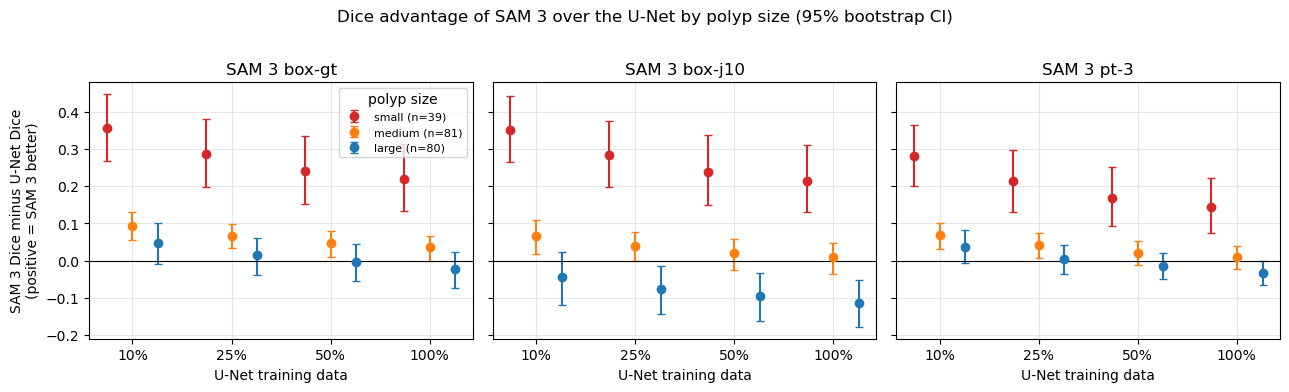

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
xs = np.arange(len(BRACKETS))
w = 0.26
cols = {"small": "tab:red", "medium": "tab:orange", "large": "tab:blue"}
for ax, s in zip(axes, STRATEGIES):
    for k, bn in enumerate(SIZE_ORDER):
        r = size_res[(size_res.metric == "dice") & (size_res.strategy == s) & (size_res.bin == bn)].set_index("bracket").loc[BRACKETS]
        ax.errorbar(xs + (k - 1) * w, r.sam3_advantage, yerr=[r.sam3_advantage - r.ci_lo, r.ci_hi - r.sam3_advantage],
                    fmt="o", color=cols[bn], capsize=3, label=f"{bn} (n={int(r.n_images.iloc[0])})")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(xs); ax.set_xticklabels([b.replace("pct", "%") for b in BRACKETS])
    ax.set_title(f"SAM 3 {s}"); ax.set_xlabel("U-Net training data"); ax.grid(alpha=0.3)
axes[0].set_ylabel("SAM 3 Dice minus U-Net Dice\n(positive = SAM 3 better)")
axes[0].legend(fontsize=8, title="polyp size")
fig.suptitle("Dice advantage of SAM 3 over the U-Net by polyp size (95% bootstrap CI)", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "size_bin_dice_advantage.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Contrast tertiles (exploratory)

Same tests on the low / medium / high contrast tertiles from Task 1.2. These are exploratory: the proxy is confounded with polyp size and failed a face-validity check (see `decisions.md`, 20 Oct). Do not make claims from this table without saying so.

In [9]:
contrast_res = run_bins(contrast, CONTRAST_ORDER, "contrast")
contrast_res.to_csv(OUT / "contrast_bin_significance.csv", index=False)
print("Boundary IoU by contrast tertile (exploratory): SAM 3 advantage [95% CI]; * = Holm p < 0.05")
show(contrast_res, "boundary_iou")

Boundary IoU by contrast tertile (exploratory): SAM 3 advantage [95% CI]; * = Holm p < 0.05


bin                                  low                    medium  \
box-gt  10pct   +0.205 [+0.147, +0.263]*  +0.155 [+0.098, +0.211]*   
        25pct   +0.151 [+0.098, +0.208]*  +0.112 [+0.064, +0.158]*   
        50pct   +0.117 [+0.061, +0.175]*   +0.069 [+0.017, +0.120]   
        100pct  +0.094 [+0.040, +0.151]*  +0.063 [+0.020, +0.104]*   
box-j10 10pct   +0.139 [+0.071, +0.205]*   +0.082 [+0.018, +0.145]   
        25pct    +0.085 [+0.022, +0.149]   +0.039 [-0.019, +0.096]   
        50pct    +0.051 [-0.014, +0.117]   -0.004 [-0.061, +0.055]   
        100pct   +0.027 [-0.035, +0.093]   -0.010 [-0.059, +0.039]   
pt-3    10pct   +0.133 [+0.079, +0.188]*  +0.104 [+0.049, +0.160]*   
        25pct    +0.080 [+0.025, +0.136]   +0.061 [+0.013, +0.111]   
        50pct    +0.046 [-0.003, +0.098]   +0.018 [-0.030, +0.067]   
        100pct   +0.022 [-0.026, +0.074]   +0.012 [-0.030, +0.052]   

bin                                 high  
box-gt  10pct   +0.174 [+0.117, +0.231]*  
        25pct   +0.134 [+0.075, +0.193]*  
        50pct    +0.096 [+0.037, +0.155]  
        100pct   +0.088 [+0.031, +0.146]  
box-j10 10pct    +0.087 [+0.019, +0.157]  
        25pct    +0.048 [-0.018, +0.115]  
        50pct    +0.009 [-0.058, +0.076]  
        100pct   +0.002 [-0.062, +0.066]  
pt-3    10pct   +0.111 [+0.050, +0.171]*  
        25pct    +0.072 [+0.014, +0.131]  
        50pct    +0.033 [-0.025, +0.091]  
        100pct   +0.026 [-0.032, +0.082]

## 7. Notes for the report (fill in after reading the tables)

- **Size.** For which size bins, brackets and prompts is SAM 3's Dice advantage significant (Holm), and where does the sign flip? Use the CI, not only the star.
- **Small bin.** Only 39 images: say which comparisons are inconclusive.
- **Boundary metrics.** Does the pattern for Boundary IoU and HD95 match Dice, or do crossovers move?
- **Contrast.** Exploratory only: state the confound and the lack of support for H2 in the predicted direction.
- **Multiplicity.** p-values are adjusted within each metric across all bins, brackets and strategies (Holm and Bonferroni both saved).

In [10]:
# ---- HD95 sensitivity: capped (primary) vs listwise exclusion of the images with a non-finite HD95 ----
# Paste as a new code cell at the END of notebooks/11_week4_per_bin_significance.ipynb and run it
# after the earlier cells (it reuses `advantage`, `summarise`, `images`, `size`, `STRATEGIES`, `BRACKETS`).
raw = pd.read_csv(ROOT / "results" / "per_image_results.csv")
bad = sorted(set(raw.loc[~np.isfinite(raw["hd95"]), "image_id"]))
print(f"{len(bad)} images have a non-finite HD95 in at least one condition; size bins: {size[bad].value_counts().to_dict()}")
assert len(bad) == 5

rng = np.random.default_rng(BOOT_SEED)
rows = []
subsets = {"all images": images,
           "small bin": [i for i in images if size[i] == "small"]}
for sub_name, ids_all in subsets.items():
    ids_excl = [i for i in ids_all if i not in set(bad)]
    for b in BRACKETS:
        for s in STRATEGIES:
            for policy, ids in [("cap (primary)", ids_all), ("exclude 5 images", ids_excl)]:
                d = advantage("hd95", b, s, ids)
                est, lo, hi, p, r, _ = summarise(d, "hd95", rng)
                rows.append({"subset": sub_name, "bracket": b, "strategy": s, "policy": policy, "n_images": len(ids),
                             "median_adv_px": est, "ci_lo": lo, "ci_hi": hi, "p_raw": p})
sens_hd95 = pd.DataFrame(rows)
wide = sens_hd95.pivot_table(index=["subset", "strategy", "bracket"], columns="policy",
                             values=["median_adv_px", "p_raw"], aggfunc="first")
wide.columns = [f"{a}|{b}" for a, b in wide.columns]
wide["sign_changes"] = np.sign(wide["median_adv_px|cap (primary)"]) != np.sign(wide["median_adv_px|exclude 5 images"])
wide["signif_changes"] = (wide["p_raw|cap (primary)"] < 0.05) != (wide["p_raw|exclude 5 images"] < 0.05)
wide = wide.reset_index()
wide.to_csv(OUT / "hd95_sensitivity.csv", index=False)
print("Comparisons:", len(wide), "| sign changes:", int(wide.sign_changes.sum()),
      "| raw p<0.05 status changes:", int(wide.signif_changes.sum()))
wide.round(3)

5 images have a non-finite HD95 in at least one condition; size bins: {'small': 5}
Comparisons: 24 | sign changes: 0 | raw p<0.05 status changes: 0


,subset,strategy,bracket,median_adv_px|cap (primary),median_adv_px|exclude 5 images,p_raw|cap (primary),p_raw|exclude 5 images,sign_changes,signif_changes
0,all images,box-gt,100pct,13.983,13.899,0.000,0.000,False,False
1,all images,box-gt,10pct,53.991,52.724,0.000,0.000,False,False
2,all images,box-gt,25pct,40.037,36.121,0.000,0.000,False,False
3,all images,box-gt,50pct,28.508,26.541,0.000,0.000,False,False
4,all images,box-j10,100pct,11.782,11.055,0.000,0.000,False,False
5,all images,box-j10,10pct,47.670,46.652,0.000,0.000,False,False
6,all images,box-j10,25pct,34.454,31.461,0.000,0.000,False,False
7,all images,box-j10,50pct,23.376,21.644,0.000,0.000,False,False
8,all images,pt-3,100pct,5.662,5.620,0.001,0.001,False,False
9,all images,pt-3,10pct,39.798,39.181,0.000,0.000,False,False
